Phase 1 - EDA and Preprocessing

In [1]:
# Install the required libraries if they are not already available
%pip install pandas numpy matplotlib seaborn scikit-learn scipy

Note: you may need to restart the kernel to use updated packages.


In [1]:

import pandas as pd
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns


from scipy import stats


np.random.seed(42)


sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# URL of the public IBM Telco Customer Churn dataset
url = (
    "https://raw.githubusercontent.com/"
    "IBM/telco-customer-churn-on-icp4d/"
    "master/data/Telco-Customer-Churn.csv"
)

# Load the CSV file into a pandas DataFrame
df = pd.read_csv(url)

# Display the first five observations
print("First five rows:")
display(df.head())

# Check the size of the dataset
print("Dataset dimensions:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and non-null counts
print("\nDataset information:")
df.info()

# Generate summary statistics for numerical and categorical columns
print("\nSummary statistics:")
display(df.describe(include="all").T)

First five rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset dimensions: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# -------------------------------------------------------
# DATA QUALITY CHECKS
# -------------------------------------------------------

# 1. Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 2. Check missing values in each column
missing = df.isnull().sum().sort_values(ascending=False)

print("\nMissing values by column:")
display(missing[missing > 0])

# 3. Check data types
print("\nData types:")
display(df.dtypes.to_frame(name="Data Type"))

# 4. Check the target variable
print("\nChurn value counts:")
display(df["Churn"].value_counts(dropna=False))

print("\nChurn proportions:")
display(
    df["Churn"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

Duplicate rows: 0

Missing values by column:


Series([], dtype: int64)


Data types:


,Data Type
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



Churn value counts:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn proportions:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

In [4]:
# Inspect the original TotalCharges data type
print("Original dtype:", df["TotalCharges"].dtype)

# Convert to numeric; invalid strings become NaN
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Count values that became missing
print(
    "Missing TotalCharges after conversion:",
    df["TotalCharges"].isna().sum()
)

# Inspect affected observations
display(
    df.loc[
        df["TotalCharges"].isna(),
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
    ].head(10)
)

Original dtype: object
Missing TotalCharges after conversion: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


Customer counts:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Customer percentages:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

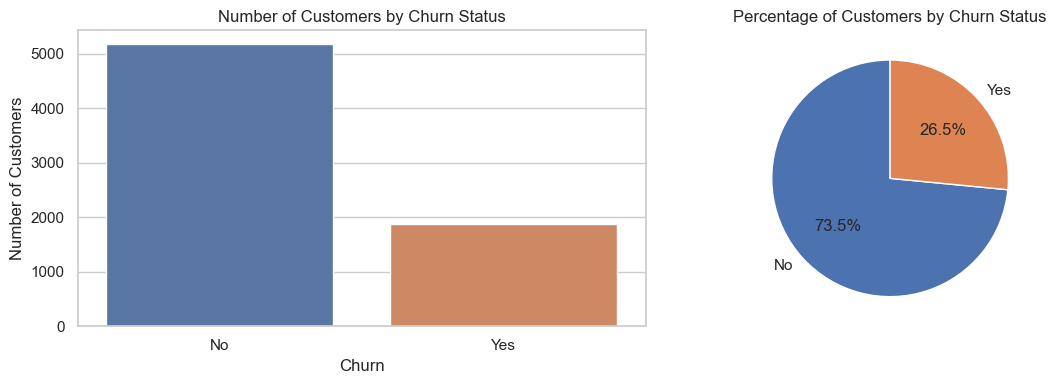

In [5]:
# -------------------------------------------------------
# TARGET VARIABLE ANALYSIS
# -------------------------------------------------------

# Count customers in each churn category
churn_counts = df["Churn"].value_counts()

# Calculate percentage of each category
churn_percentages = (
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
)

print("Customer counts:")
display(churn_counts)

print("\nCustomer percentages:")
display(churn_percentages.round(2))

# Visualize the distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Number of Customers by Churn Status")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Number of Customers")

axes[1].pie(
    churn_counts,
    labels=churn_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Percentage of Customers by Churn Status")

plt.tight_layout()
plt.show()

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


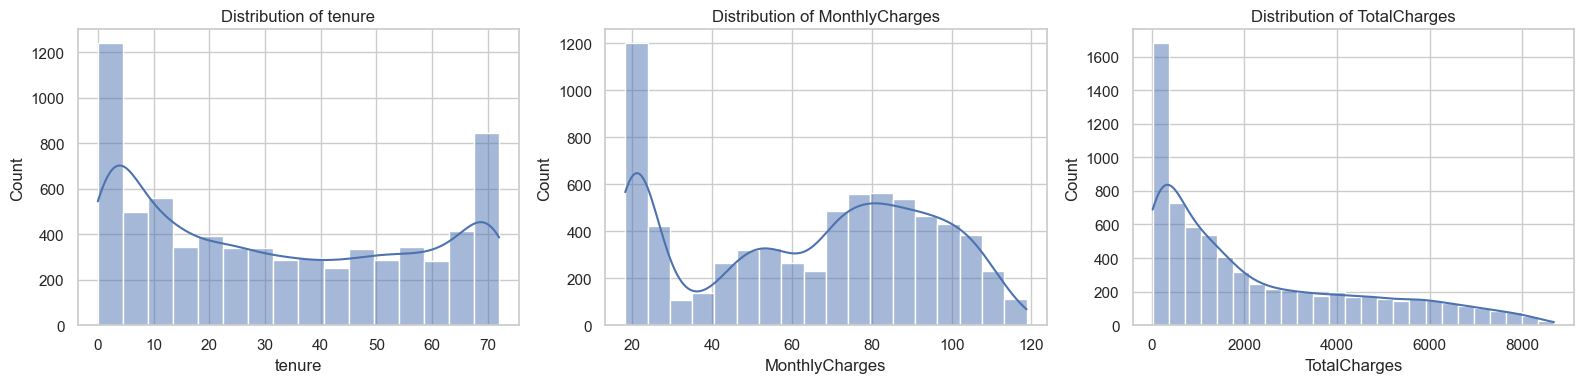

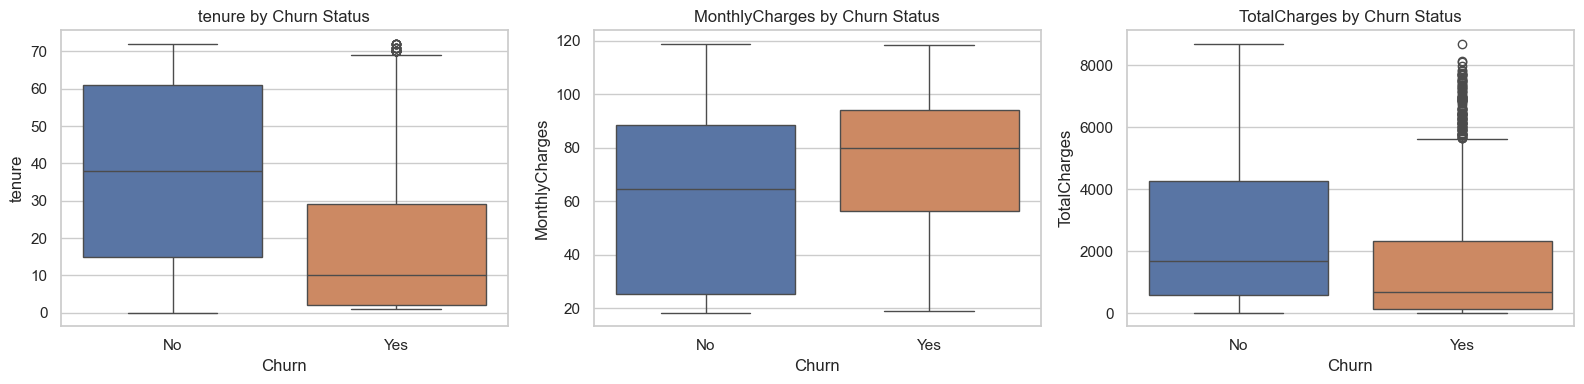

In [6]:
# -------------------------------------------------------
# NUMERICAL FEATURE DISTRIBUTIONS
# -------------------------------------------------------

numeric_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Display descriptive statistics
display(df[numeric_cols].describe().T)

# Histograms
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for col, ax in zip(numeric_cols, axes):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

# Compare distributions by churn status
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for col, ax in zip(numeric_cols, axes):
    sns.boxplot(
        data=df,
        x="Churn",
        y=col,
        hue="Churn",
        legend=False,
        ax=ax
    )
    ax.set_title(f"{col} by Churn Status")

plt.tight_layout()
plt.show()

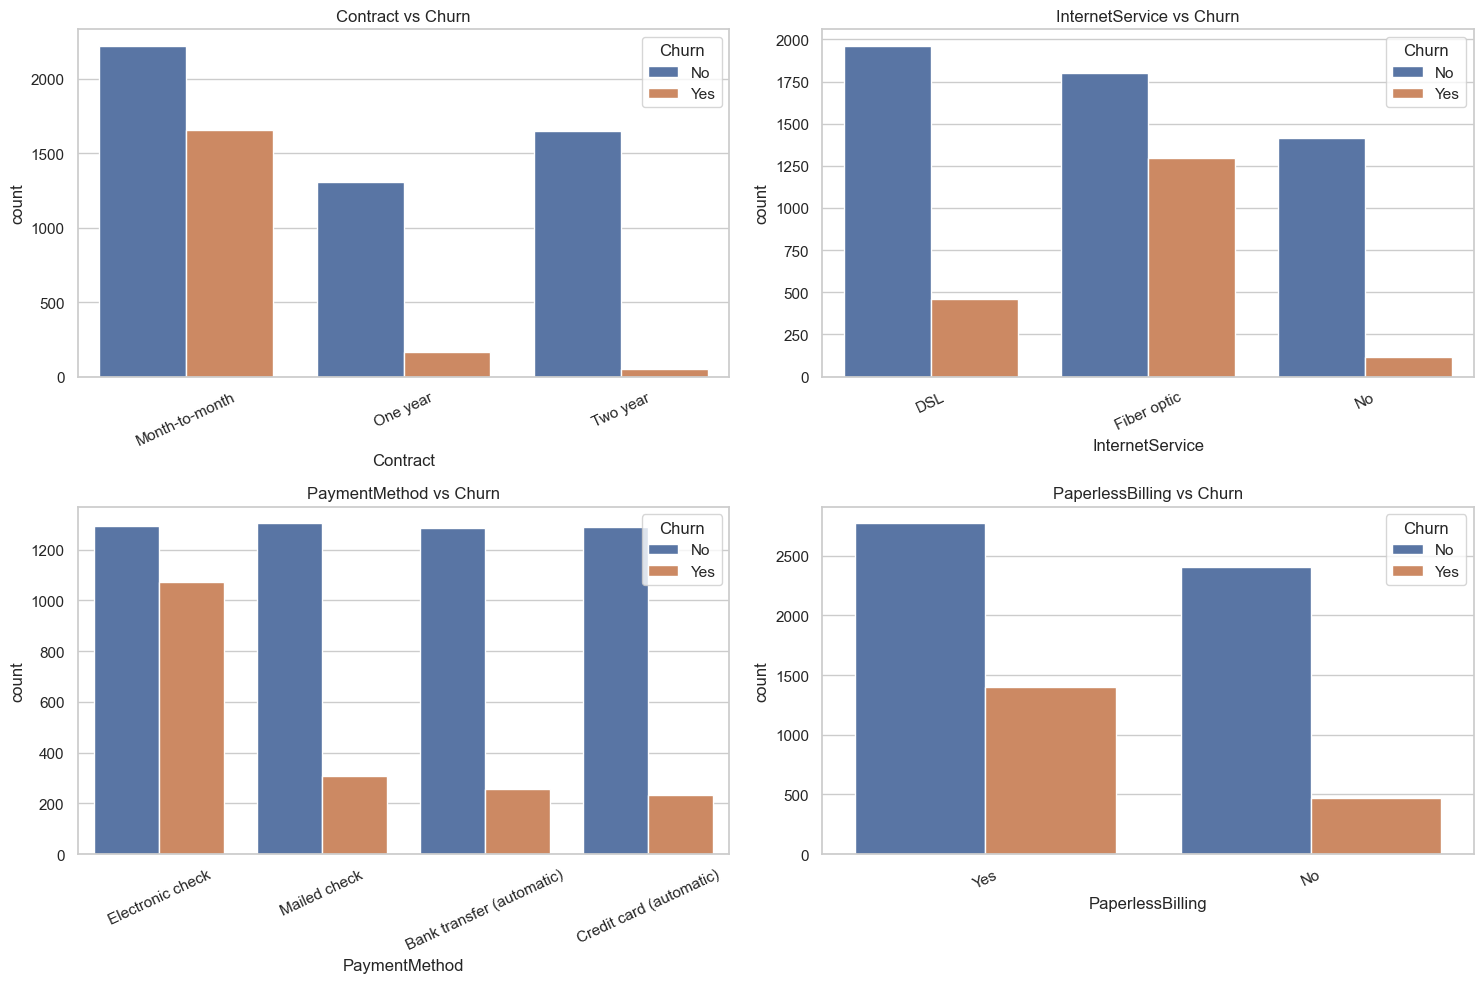


Churn rate by Contract:


Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn Rate (%), dtype: float64


Churn rate by InternetService:


InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn Rate (%), dtype: float64


Churn rate by PaymentMethod:


PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn Rate (%), dtype: float64


Churn rate by PaperlessBilling:


PaperlessBilling
Yes    33.57
No     16.33
Name: Churn Rate (%), dtype: float64

In [7]:
# -------------------------------------------------------
# CATEGORICAL FEATURE ANALYSIS
# -------------------------------------------------------

categorical_cols = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "PaperlessBilling"
]

# Count plots for categorical features
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for col, ax in zip(categorical_cols, axes):
    sns.countplot(
        data=df,
        x=col,
        hue="Churn",
        ax=ax
    )
    ax.set_title(f"{col} vs Churn")
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

# Calculate churn rate within each category
for col in categorical_cols:
    print(f"\nChurn rate by {col}:")

    churn_rate = (
        df.groupby(col, dropna=False)["Churn"]
        .apply(lambda s: s.eq("Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    display(churn_rate.round(2).rename("Churn Rate (%)"))

In [8]:
# -------------------------------------------------------
# DATA CLEANING
# -------------------------------------------------------

# Work on a copy so the original data remains available
df_clean = df.copy()

# Remove exact duplicate rows, if present
df_clean = df_clean.drop_duplicates().copy()

# Handle missing TotalCharges for customers with zero tenure
zero_tenure_missing = (
    df_clean["TotalCharges"].isna()
    & df_clean["tenure"].eq(0)
)

df_clean.loc[zero_tenure_missing, "TotalCharges"] = 0

# Investigate any remaining missing TotalCharges values
remaining_missing = df_clean["TotalCharges"].isna().sum()

print("Remaining missing TotalCharges:", remaining_missing)

# If other missing values remain, use the median as a simple
# fallback for this exploratory dataset.
# Later, model preprocessing will be fitted only on training data.
if remaining_missing > 0:
    df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(
        df_clean["TotalCharges"].median()
    )

# Verify data quality after cleaning
print("\nMissing values after TotalCharges cleaning:")
display(
    df_clean.isnull().sum()
    .loc[lambda s: s > 0]
)

print("\nCleaned dataset shape:", df_clean.shape)
print("Exact duplicate rows:", df_clean.duplicated().sum())

Remaining missing TotalCharges: 0

Missing values after TotalCharges cleaning:


Series([], dtype: int64)


Cleaned dataset shape: (7043, 21)
Exact duplicate rows: 0


In [9]:
# -------------------------------------------------------
# INITIAL BUSINESS SUMMARY
# -------------------------------------------------------

total_customers = len(df_clean)

churned_customers = (df_clean["Churn"] == "Yes").sum()

churn_rate = (
    churned_customers / total_customers * 100
    if total_customers > 0 else np.nan
)

print("=" * 50)
print("CUSTOMER CHURN: INITIAL BUSINESS SUMMARY")
print("=" * 50)

print(f"Total customer records: {total_customers}")
print(f"Customers who churned: {churned_customers}")
print(f"Overall churn rate: {churn_rate:.2f}%")

print("\nAverage monthly charges by churn status:")
display(
    df_clean.groupby("Churn")["MonthlyCharges"]
    .mean()
    .round(2)
)

print("\nAverage tenure by churn status:")
display(
    df_clean.groupby("Churn")["tenure"]
    .mean()
    .round(2)
)

print("\nAverage total charges by churn status:")
display(
    df_clean.groupby("Churn")["TotalCharges"]
    .mean()
    .round(2)
)

# Save a cleaned copy for later project stages
df_clean.to_csv("telco_churn_cleaned.csv", index=False)

print("\nCleaned dataset saved successfully.")

CUSTOMER CHURN: INITIAL BUSINESS SUMMARY
Total customer records: 7043
Customers who churned: 1869
Overall churn rate: 26.54%

Average monthly charges by churn status:


Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


Average tenure by churn status:


Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64


Average total charges by churn status:


Churn
No     2549.91
Yes    1531.80
Name: TotalCharges, dtype: float64


Cleaned dataset saved successfully.


Phase 2 - Statistical Analysis 

In [10]:
# ============================================================
# CHI-SQUARE TEST OF INDEPENDENCE: CONTRACT TYPE AND CHURN
# ============================================================

import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

# Create a contingency table
contingency_table = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"]
)

print("Observed frequency table:")
display(contingency_table)

# Perform the chi-square test
chi2_stat, p_value, degrees_freedom, expected = chi2_contingency(
    contingency_table
)

# Display expected frequencies
expected_table = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print("\nExpected frequencies under independence:")
display(expected_table.round(2))

print(f"\nChi-square statistic: {chi2_stat:.4f}")
print(f"Degrees of freedom: {degrees_freedom}")
print(f"P-value: {p_value:.6g}")

# Interpret the result
alpha = 0.05

if p_value < alpha:
    print(
        "\nDecision: Reject H0. There is evidence of an association "
        "between contract type and churn."
    )
else:
    print(
        "\nDecision: Fail to reject H0. There is insufficient "
        "evidence of an association between contract type and churn."
    )

Observed frequency table:


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48



Expected frequencies under independence:


Churn,No,Yes
Contract,,
Month-to-month,2846.69,1028.31
One year,1082.11,390.89
Two year,1245.20,449.80



Chi-square statistic: 1184.5966
Degrees of freedom: 2
P-value: 5.86304e-258

Decision: Reject H0. There is evidence of an association between contract type and churn.


In [11]:
# Cramer's V measures the strength of association
n = contingency_table.to_numpy().sum()

r, c = contingency_table.shape

cramers_v = np.sqrt(
    chi2_stat / (n * min(r - 1, c - 1))
)

print(f"Cramer's V: {cramers_v:.4f}")

Cramer's V: 0.4101


,Total_Customers,Churned_Customers,Churn_Rate_Percent
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


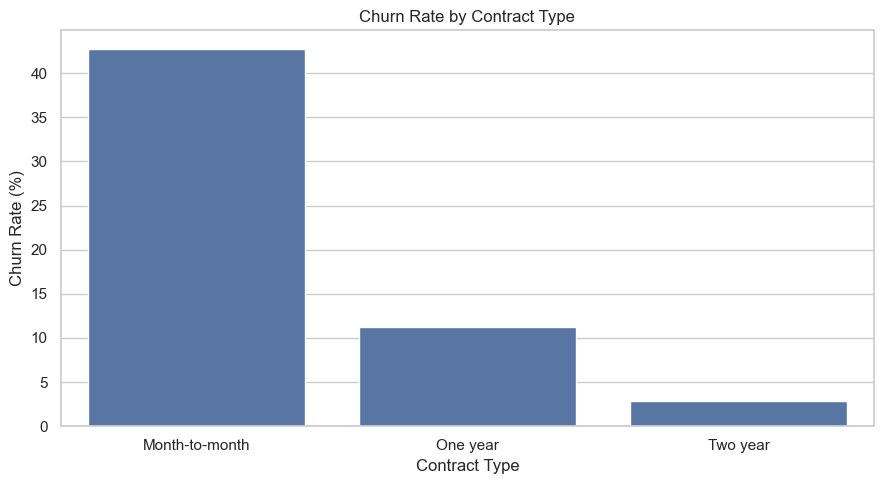

In [12]:
# ============================================================
# CHURN RATE BY CONTRACT TYPE
# ============================================================

contract_summary = (
    df_clean.groupby("Contract", observed=True)
    .agg(
        Total_Customers=("Churn", "size"),
        Churned_Customers=(
            "Churn",
            lambda s: (s == "Yes").sum()
        )
    )
)

contract_summary["Churn_Rate_Percent"] = (
    contract_summary["Churned_Customers"]
    / contract_summary["Total_Customers"]
    * 100
)

contract_summary = contract_summary.sort_values(
    "Churn_Rate_Percent",
    ascending=False
)

display(contract_summary.round(2))

# Visualize the churn rates
plt.figure(figsize=(9, 5))

sns.barplot(
    data=contract_summary.reset_index(),
    x="Contract",
    y="Churn_Rate_Percent"
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

Correlation matrix:


,tenure,MonthlyCharges,TotalCharges
tenure,1.000,0.248,0.826
MonthlyCharges,0.248,1.000,0.651
TotalCharges,0.826,0.651,1.000


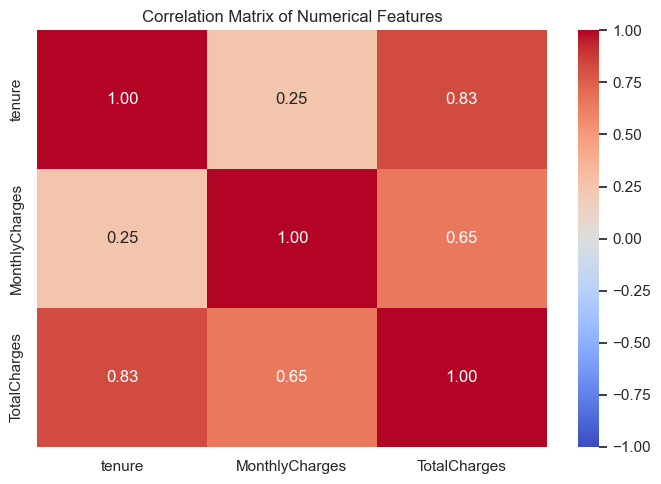

In [13]:
# ============================================================
# CORRELATION ANALYSIS
# ============================================================

numeric_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

correlation_matrix = df_clean[numeric_cols].corr(
    method="pearson"
)

print("Correlation matrix:")
display(correlation_matrix.round(3))

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

Phase 3 - Model Building

In [14]:
# ============================================================
# FEATURE PREPARATION AND TRAIN-TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# Work on a fresh copy
model_df = df_clean.copy()

# Remove the customer identifier
model_df = model_df.drop(columns=["customerID"], errors="ignore")

# Separate predictors and response
X = model_df.drop(columns=["Churn"])
y = model_df["Churn"].map({"No": 0, "Yes": 1})

# Check target encoding
if y.isna().any():
    raise ValueError("Unexpected or missing values in the Churn target.")

print("Predictor dimensions:", X.shape)
print("Target dimensions:", y.shape)

print("\nTarget distribution:")
display(y.value_counts().rename(index={0: "No Churn", 1: "Churn"}))

# Split before fitting any preprocessing steps
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining churn proportion:", round(y_train.mean(), 4))
print("Testing churn proportion:", round(y_test.mean(), 4))

Predictor dimensions: (7043, 19)
Target dimensions: (7043,)

Target distribution:


Churn
No Churn    5174
Churn       1869
Name: count, dtype: int64


Training observations: 5634
Testing observations: 1409

Training churn proportion: 0.2654
Testing churn proportion: 0.2654


In [15]:
# ============================================================
# PREPROCESSING PIPELINE
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Identify numerical and categorical columns from training data
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

# Numerical preprocessing:
# 1. Fill missing values using training-set medians.
# 2. Standardize numerical features.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing:
# 1. Fill missing values using the most frequent category.
# 2. Convert categories into indicator columns.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preprocessing to each type of column
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Combine preprocessing and logistic regression
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

print("Preprocessing pipeline created successfully.")

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Preprocessing pipeline created successfully.


In [16]:
# ============================================================
# TRAIN LOGISTIC REGRESSION
# ============================================================

# Fit preprocessing and model using training data only
logistic_model.fit(X_train, y_train)

print("Logistic regression training completed.")

# Predict class labels on unseen test data
y_pred = logistic_model.predict(X_test)

# Predict probability of churn (class 1)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].to_list())

print("\nFirst 10 predicted labels:")
print(y_pred[:10])

print("\nFirst 10 predicted churn probabilities:")
print(np.round(y_prob[:10], 3))

Logistic regression training completed.

First 10 actual labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

First 10 predicted labels:
[0 1 0 0 0 1 0 0 0 0]

First 10 predicted churn probabilities:
[0.046 0.684 0.059 0.402 0.021 0.603 0.448 0.13  0.003 0.395]


LOGISTIC REGRESSION: TEST PERFORMANCE
---------------------------------------------
Accuracy : 0.8055
Precision: 0.6572
Recall   : 0.5588
F1-score : 0.6040
ROC-AUC  : 0.8421

Detailed classification report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



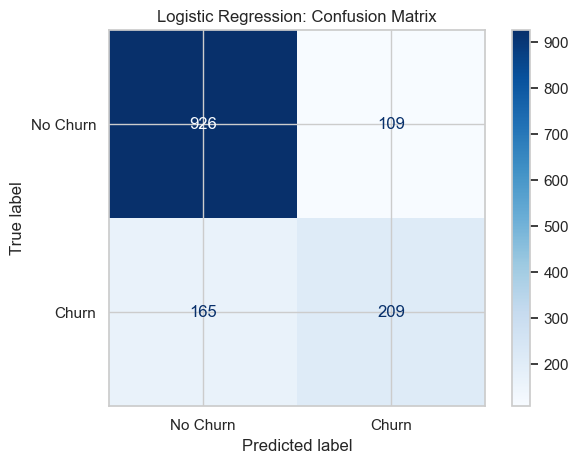

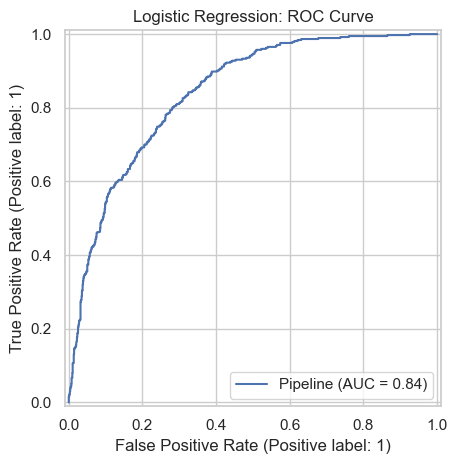

In [17]:
# ============================================================
# MODEL EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("LOGISTIC REGRESSION: TEST PERFORMANCE")
print("-" * 45)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Logistic Regression: Confusion Matrix")
plt.tight_layout()
plt.show()

# ROC curve
RocCurveDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test
)

plt.title("Logistic Regression: ROC Curve")
plt.tight_layout()
plt.show()

Phase 4  - Model Comparison

In [18]:
# ============================================================
# MODEL COMPARISON: LOGISTIC REGRESSION, TREE, RANDOM FOREST
# ============================================================

import pandas as pd
import numpy as np

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# ------------------------------------------------------------
# 1. Identify feature types from the training data
# ------------------------------------------------------------

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()


# ------------------------------------------------------------
# 2. Create a fresh preprocessing pipeline for each model
# ------------------------------------------------------------

def create_preprocessor(scale_numeric=True):

    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale_numeric:
        numeric_steps.append(
            ("scaler", StandardScaler())
        )

    numeric_transformer = Pipeline(steps=numeric_steps)

    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer(transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ])


# ------------------------------------------------------------
# 3. Define the candidate models
# ------------------------------------------------------------

models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", create_preprocessor(scale_numeric=True)),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline(steps=[
        ("preprocessor", create_preprocessor(scale_numeric=False)),
        ("classifier", DecisionTreeClassifier(
            max_depth=5,
            min_samples_leaf=20,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline(steps=[
        ("preprocessor", create_preprocessor(scale_numeric=False)),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=10,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

print("Models prepared:")
for model_name in models:
    print("-", model_name)

Models prepared:
- Logistic Regression
- Decision Tree
- Random Forest


In [19]:
# ============================================================
# FIVE-FOLD STRATIFIED CROSS-VALIDATION
# ============================================================

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for model_name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "roc_auc": "roc_auc",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1"
        },
        n_jobs=-1,
        return_train_score=False
    )

    cv_results.append({
        "Model": model_name,
        "Mean ROC-AUC": scores["test_roc_auc"].mean(),
        "ROC-AUC SD": scores["test_roc_auc"].std(),
        "Mean Precision": scores["test_precision"].mean(),
        "Mean Recall": scores["test_recall"].mean(),
        "Mean F1": scores["test_f1"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    "Mean ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(cv_results_df.round(4))

,Model,Mean ROC-AUC,ROC-AUC SD,Mean Precision,Mean Recall,Mean F1
0,Random Forest,0.8463,0.0081,0.5497,0.7431,0.6318
1,Logistic Regression,0.8462,0.0126,0.6529,0.5431,0.5923
2,Decision Tree,0.8275,0.0119,0.6345,0.5137,0.5656


In [20]:
# ============================================================
# FINAL TEST-SET COMPARISON
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

test_results = []
fitted_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model in models.items():

    # Fit on training data
    model.fit(X_train, y_train)

    # Predict test-set classes and probabilities
    y_hat = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1]

    # Save fitted models and predictions
    fitted_models[model_name] = model
    test_predictions[model_name] = y_hat
    test_probabilities[model_name] = y_score

    # Calculate metrics
    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_hat),
        "Precision": precision_score(
            y_test, y_hat, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_hat, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_hat, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_score)
    })

test_results_df = pd.DataFrame(test_results)

display(
    test_results_df.sort_values(
        "ROC-AUC",
        ascending=False
    ).reset_index(drop=True).round(4)
)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest,0.7637,0.5392,0.7540,0.6288,0.8422
1,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421
2,Decision Tree,0.7984,0.6347,0.5668,0.5989,0.8282


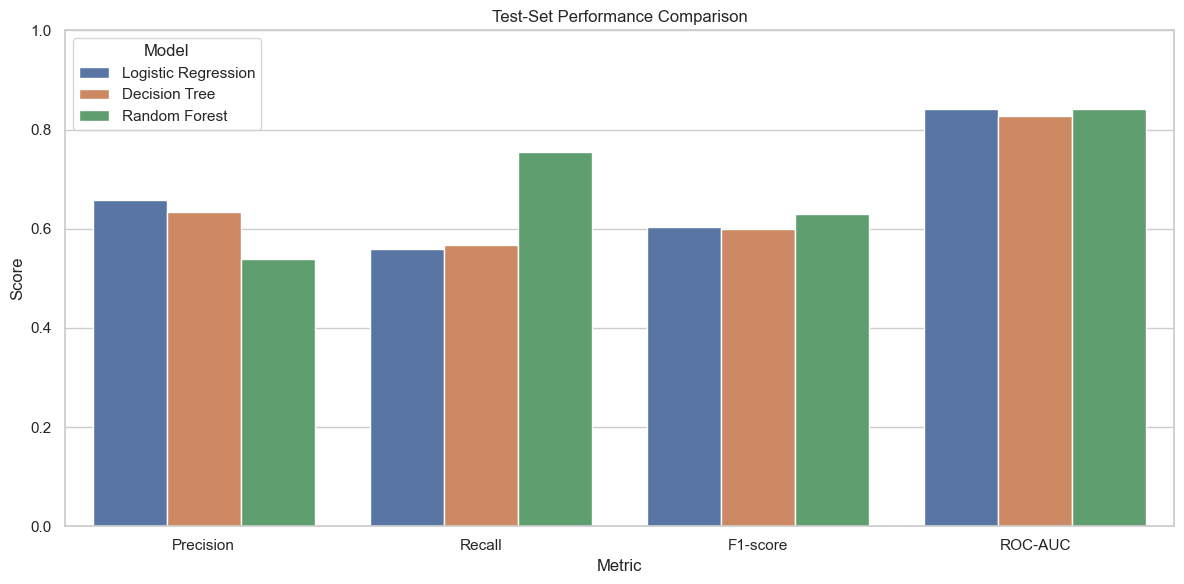

In [21]:
# Compare classification metrics across models

metrics_to_plot = [
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]

plot_df = test_results_df.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.ylim(0, 1)
plt.title("Test-Set Performance Comparison")
plt.tight_layout()
plt.show()

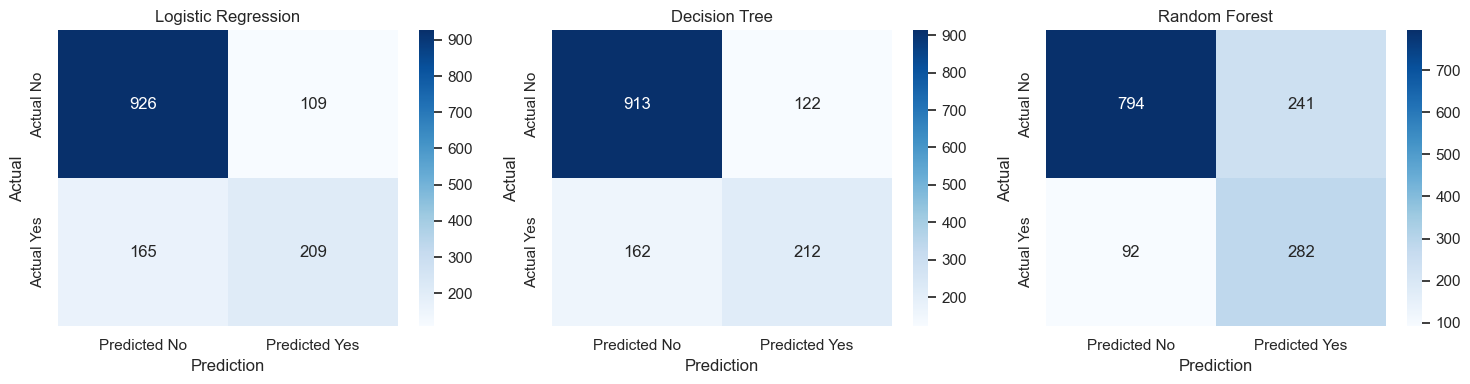

In [22]:
# ============================================================
# CONFUSION MATRICES
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (model_name, y_hat) in zip(
    axes,
    test_predictions.items()
):

    cm = confusion_matrix(
        y_test,
        y_hat,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Predicted No", "Predicted Yes"],
        yticklabels=["Actual No", "Actual Yes"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Prediction")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
# Choosing Random Forest as appropriate model 

,Threshold,Precision,Recall,F1-score
0,0.3,0.4486,0.8877,0.5961
1,0.4,0.4975,0.8128,0.6173
2,0.5,0.5392,0.7540,0.6288
3,0.6,0.5848,0.6364,0.6095
4,0.7,0.6763,0.5027,0.5767


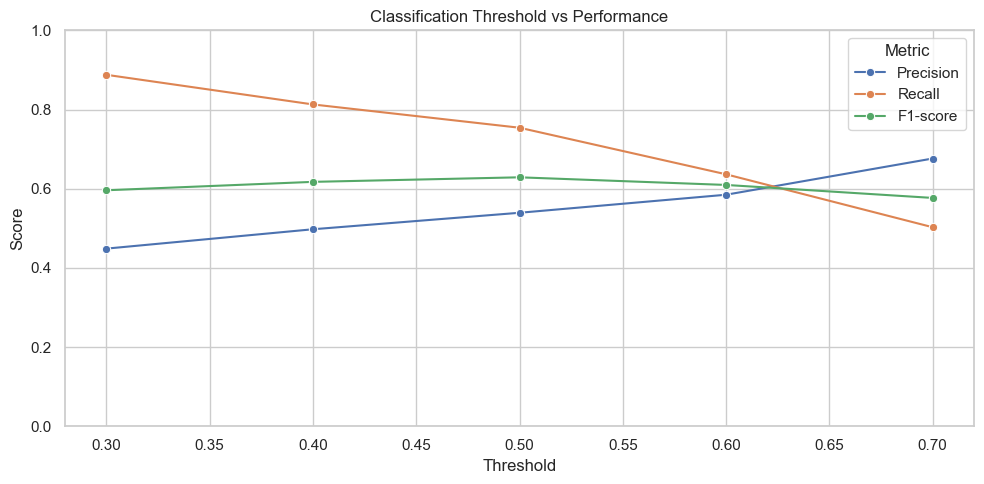

In [23]:
# ============================================================
# THRESHOLD ANALYSIS FOR RANDOM FOREST
# ============================================================

from sklearn.metrics import precision_score, recall_score, f1_score

rf_prob = test_probabilities["Random Forest"]

threshold_results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:

    threshold_pred = (
        rf_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, threshold_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, threshold_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, threshold_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

threshold_plot = threshold_df.melt(
    id_vars="Threshold",
    value_vars=["Precision", "Recall", "F1-score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=threshold_plot,
    x="Threshold",
    y="Score",
    hue="Metric",
    marker="o"
)

plt.title("Classification Threshold vs Performance")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

,Feature,Importance
36,cat__Contract_Month-to-month,0.1340
1,num__tenure,0.1241
3,num__TotalCharges,0.0971
18,cat__OnlineSecurity_No,0.0662
2,num__MonthlyCharges,0.0652
38,cat__Contract_Two year,0.0646
27,cat__TechSupport_No,0.0531
16,cat__InternetService_Fiber optic,0.0521
43,cat__PaymentMethod_Electronic check,0.0374
37,cat__Contract_One year,0.0196


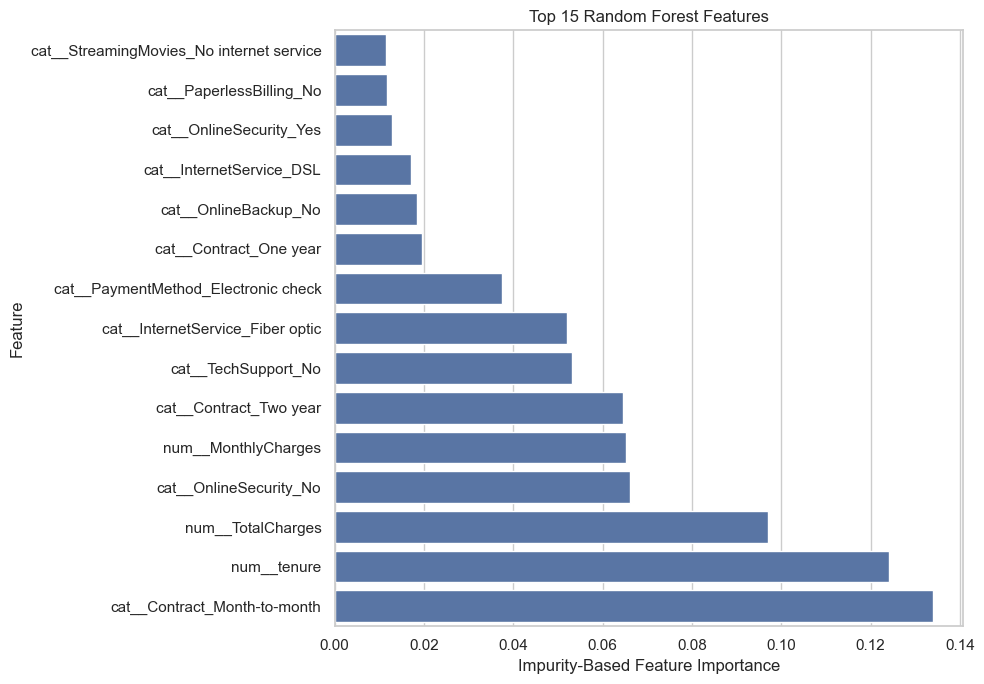

In [24]:
# ============================================================
# RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

rf_pipeline = fitted_models["Random Forest"]

# Retrieve names of the transformed features
rf_feature_names = (
    rf_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Retrieve the random forest's feature importances
rf_importances = (
    rf_pipeline
    .named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importances
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

top_features = importance_df.head(15).sort_values(
    "Importance",
    ascending=True
)

display(
    importance_df.head(15).round(4)
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Random Forest Features")
plt.xlabel("Impurity-Based Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

Phase 4 - Creating Customer Churn Risk List

In [25]:
# ============================================================
# CUSTOMER CHURN RISK RANKING
# ============================================================

# Create a table using the held-out test customers
risk_df = pd.DataFrame({
    "customerID": df_clean.loc[X_test.index, "customerID"],
    "Actual_Churn": y_test.map({0: "No", 1: "Yes"}),
    "Churn_Probability": test_probabilities["Random Forest"]
}, index=X_test.index)

# Rank customers from highest to lowest predicted risk
risk_df = risk_df.sort_values(
    "Churn_Probability",
    ascending=False
)

# Assign risk bands for prioritization
risk_df["Risk_Band"] = pd.cut(
    risk_df["Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.0],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

print("Top 20 highest-risk test customers:")
display(risk_df.head(20))

print("\nCustomer counts by risk band:")
display(
    risk_df["Risk_Band"]
    .value_counts()
    .reindex(["High", "Medium", "Low"])
)

# Export the risk ranking
risk_df.to_csv(
    "customer_churn_risk_ranking.csv",
    index=False
)

print("\nRisk ranking exported successfully.")

Top 20 highest-risk test customers:


,customerID,Actual_Churn,Churn_Probability,Risk_Band
6866,0295-PPHDO,Yes,0.947688,High
4585,1069-XAIEM,Yes,0.942538,High
3380,5178-LMXOP,Yes,0.940781,High
6623,9248-OJYKK,Yes,0.935913,High
3727,9057-SIHCH,Yes,0.934025,High
2797,6023-YEBUP,Yes,0.931249,High
809,1820-TQVEV,Yes,0.926691,High
1731,8375-DKEBR,Yes,0.925934,High
3346,2545-EBUPK,No,0.925166,High
2729,1143-NMNQJ,Yes,0.923881,High



Customer counts by risk band:


Risk_Band
High      407
Medium    333
Low       669
Name: count, dtype: int64


Risk ranking exported successfully.


In [26]:
# ============================================================
# ILLUSTRATIVE RETENTION BUSINESS-VALUE SCENARIO
# ============================================================

# Hypothetical business assumptions, not measured results
customers_contacted = 500
retention_cost_per_customer = 20
monthly_contribution_per_customer = 50
expected_retention_period_months = 6
assumed_incremental_retention_probability = 0.10

# Calculate campaign costs
campaign_cost = (
    customers_contacted * retention_cost_per_customer
)

# Estimate the number of additional customers retained
additional_customers_retained = (
    customers_contacted
    * assumed_incremental_retention_probability
)

# Estimate contribution from those additional retained customers
estimated_contribution = (
    additional_customers_retained
    * monthly_contribution_per_customer
    * expected_retention_period_months
)

# Calculate estimated net value
estimated_net_value = estimated_contribution - campaign_cost

print(f"Campaign cost: {campaign_cost:.2f}")
print(
    "Assumed additional customers retained:",
    f"{additional_customers_retained:.0f}"
)
print(f"Estimated contribution: {estimated_contribution:.2f}")
print(f"Estimated net value: {estimated_net_value:.2f}")

Campaign cost: 10000.00
Assumed additional customers retained: 50
Estimated contribution: 15000.00
Estimated net value: 5000.00


Phase 5 - SQL analytics, customer segmentation and business recommendations

In [27]:
# ============================================================
# SQL BUSINESS ANALYTICS: DATABASE SETUP
# ============================================================

import sqlite3
import pandas as pd

# Create an SQLite database in memory
conn = sqlite3.connect(":memory:")

# Load the cleaned customer data into a SQL table
df_clean.to_sql(
    "customers",
    conn,
    if_exists="replace",
    index=False
)

# Verify that the table was created
query = """
SELECT COUNT(*) AS total_customers
FROM customers;
"""

display(pd.read_sql_query(query, conn))

,total_customers
0,7043


In [29]:
# Query 1: Overall churn rate
overall_query = """
SELECT
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS churn_rate_percent
FROM customers;
"""

print("Overall churn:")
display(pd.read_sql_query(overall_query, conn))


# Query 2: Churn by contract
contract_query = """
SELECT
    Contract,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS churn_rate_percent
FROM customers
GROUP BY Contract
ORDER BY churn_rate_percent DESC;
"""

print("Churn by contract:")
display(pd.read_sql_query(contract_query, conn))


# Query 3: Churn by tenure group
tenure_query = """
SELECT
    CASE
        WHEN tenure <= 12 THEN '0-12 months'
        WHEN tenure <= 36 THEN '13-36 months'
        ELSE '37+ months'
    END AS tenure_group,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS churn_rate_percent
FROM customers
GROUP BY tenure_group
ORDER BY
    CASE tenure_group
        WHEN '0-12 months' THEN 1
        WHEN '13-36 months' THEN 2
        ELSE 3
    END;
"""

print("Churn by tenure:")
display(pd.read_sql_query(tenure_query, conn))


# Query 4: Characteristic comparison of charges and churn
comp_query = """
SELECT
    Churn,
    COUNT(*) AS customer_count,
    ROUND(AVG(MonthlyCharges), 2) AS avg_monthly_charges,
    ROUND(AVG(tenure), 2) AS avg_tenure,
    ROUND(AVG(TotalCharges), 2) AS avg_total_charges
FROM customers
GROUP BY Churn;
"""

print("Characteristic comparison of charges and churn")
display(pd.read_sql_query(comp_query, conn))


# Query 5: highest-churn payment methods
pay_query = """
SELECT
    PaymentMethod,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        AS churned_customers,
    ROUND(
        100.0 * SUM(
            CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END
        ) / COUNT(*),
        2
    ) AS churn_rate_percent
FROM customers
GROUP BY PaymentMethod
HAVING COUNT(*) >= 100
ORDER BY churn_rate_percent DESC;
"""

print("Highest-churn payment methods")
display(pd.read_sql_query(pay_query, conn))

Overall churn:


,total_customers,churned_customers,churn_rate_percent
0,7043,1869,26.54


Churn by contract:


,Contract,total_customers,churned_customers,churn_rate_percent
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


Churn by tenure:


,tenure_group,total_customers,churned_customers,churn_rate_percent
0,0-12 months,2186,1037,47.44
1,13-36 months,1856,474,25.54
2,37+ months,3001,358,11.93


Characteristic comparison of charges and churn


,Churn,customer_count,avg_monthly_charges,avg_tenure,avg_total_charges
0,No,5174,61.27,37.57,2549.91
1,Yes,1869,74.44,17.98,1531.80


Highest-churn payment methods


,PaymentMethod,total_customers,churned_customers,churn_rate_percent
0,Electronic check,2365,1071,45.29
1,Mailed check,1612,308,19.11
2,Bank transfer (automatic),1544,258,16.71
3,Credit card (automatic),1522,232,15.24


In [30]:
# ============================================================
# K-MEANS CUSTOMER SEGMENTATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Select numerical variables for the initial segmentation
segment_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Create a separate clustering dataset
segment_data = df_clean[segment_features].copy()

# Check data quality
print("Missing values:")
display(segment_data.isna().sum())

print("\nSummary statistics:")
display(segment_data.describe().round(2))

# Standardize the variables
scaler = StandardScaler()

segment_scaled = scaler.fit_transform(segment_data)

print("Standardized clustering data shape:", segment_scaled.shape)

Missing values:


tenure            0
MonthlyCharges    0
TotalCharges      0
dtype: int64


Summary statistics:


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


Standardized clustering data shape: (7043, 3)


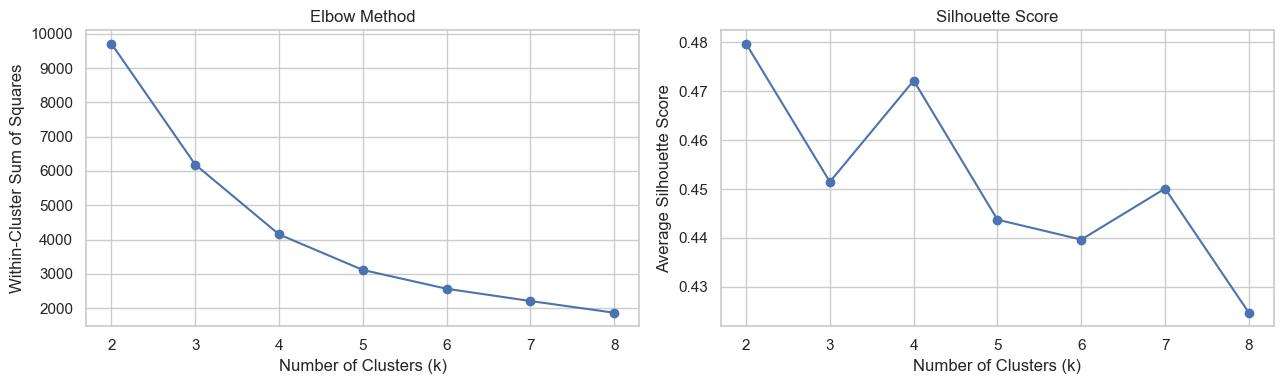

,k,Inertia,Silhouette_Score
0,2,9712.1120,0.4797
1,3,6186.1869,0.4515
2,4,4148.4825,0.4722
3,5,3111.4022,0.4437
4,6,2562.9284,0.4397
5,7,2204.4482,0.4501
6,8,1863.2142,0.4247


In [31]:
# ============================================================
# CHOOSING THE NUMBER OF CLUSTERS
# ============================================================

k_values = range(2, 9)

inertia_values = []
silhouette_values = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(segment_scaled)

    inertia_values.append(kmeans.inertia_)

    silhouette_values.append(
        silhouette_score(segment_scaled, cluster_labels)
    )

# Plot both diagnostics
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    list(k_values),
    inertia_values,
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Within-Cluster Sum of Squares")

axes[1].plot(
    list(k_values),
    silhouette_values,
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Average Silhouette Score")

plt.tight_layout()
plt.show()

# Display the numerical results
cluster_selection = pd.DataFrame({
    "k": list(k_values),
    "Inertia": inertia_values,
    "Silhouette_Score": silhouette_values
})

display(cluster_selection.round(4))

,Customer_Count,Average_Tenure,Average_Monthly_Charges,Average_Total_Charges,Churn_Rate
Cluster,,,,,
0,1703,10.21,31.78,302.15,24.66
1,1904,59.53,93.31,5548.65,15.39
2,2276,15.42,80.78,1251.17,48.24
3,1160,53.57,34.91,1835.62,5.00


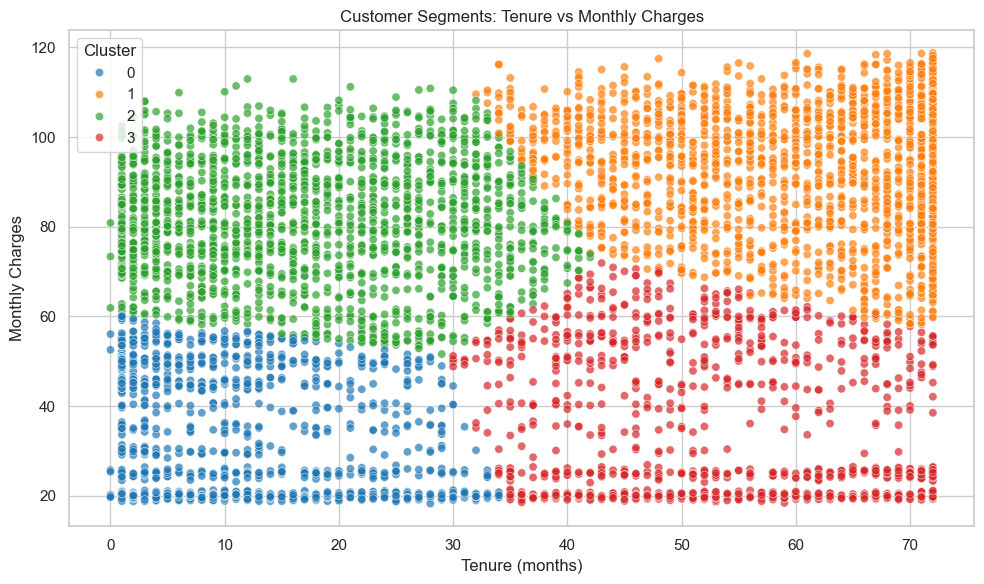

In [32]:
# ============================================================
# FIT K-MEANS AND PROFILE CUSTOMER SEGMENTS
# ============================================================

chosen_k = 4  # Initial choice; validate using the plots above

kmeans_final = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(segment_scaled)

# Add cluster labels to a separate analysis table
segmented_df = df_clean.copy()
segmented_df["Cluster"] = cluster_labels

# Profile the clusters using original, interpretable units
cluster_profile = (
    segmented_df.groupby("Cluster")
    .agg(
        Customer_Count=("customerID", "size"),
        Average_Tenure=("tenure", "mean"),
        Average_Monthly_Charges=("MonthlyCharges", "mean"),
        Average_Total_Charges=("TotalCharges", "mean"),
        Churn_Rate=(
            "Churn",
            lambda s: (s == "Yes").mean() * 100
        )
    )
    .round(2)
)

display(cluster_profile)

# Visualize two dimensions of the segmentation
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=segmented_df,
    x="tenure",
    y="MonthlyCharges",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)

plt.title("Customer Segments: Tenure vs Monthly Charges")
plt.xlabel("Tenure (months)")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

In [33]:
# ============================================================
# COMBINE RANDOM FOREST RISK AND CUSTOMER SEGMENTS
# ============================================================

# Use the fitted random forest selected in Phase 3
rf_pipeline = fitted_models["Random Forest"]

# Predict probabilities for held-out test customers
rf_test_probabilities = rf_pipeline.predict_proba(X_test)[:, 1]

# Get corresponding customer IDs and cluster labels
risk_analysis = pd.DataFrame({
    "customerID": df_clean.loc[X_test.index, "customerID"].values,
    "Cluster": segmented_df.loc[X_test.index, "Cluster"].values,
    "Actual_Churn": y_test.values,
    "Predicted_Churn_Probability": rf_test_probabilities
}, index=X_test.index)

# Assign illustrative risk bands
risk_analysis["Risk_Band"] = pd.cut(
    risk_analysis["Predicted_Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.0],
    labels=["Low", "Medium", "High"]
)

print("Highest-risk customers in the test set:")
display(
    risk_analysis.sort_values(
        "Predicted_Churn_Probability",
        ascending=False
    ).head(20)
)

# Summarize risk and actual churn by segment
segment_risk_summary = (
    risk_analysis.groupby("Cluster", observed=True)
    .agg(
        Customers=("customerID", "size"),
        Average_Predicted_Risk=(
            "Predicted_Churn_Probability", "mean"
        ),
        Actual_Churn_Rate=(
            "Actual_Churn", "mean"
        ),
        High_Risk_Customers=(
            "Risk_Band", lambda s: (s == "High").sum()
        )
    )
)

segment_risk_summary["Actual_Churn_Rate"] *= 100
segment_risk_summary["Average_Predicted_Risk"] *= 100

display(segment_risk_summary.round(2))

# Export the combined analysis
risk_analysis.to_csv(
    "customer_risk_and_segments.csv",
    index=False
)

Highest-risk customers in the test set:


,customerID,Cluster,Actual_Churn,Predicted_Churn_Probability,Risk_Band
6866,0295-PPHDO,2,1,0.947688,High
4585,1069-XAIEM,2,1,0.942538,High
3380,5178-LMXOP,2,1,0.940781,High
6623,9248-OJYKK,2,1,0.935913,High
3727,9057-SIHCH,2,1,0.934025,High
2797,6023-YEBUP,2,1,0.931249,High
809,1820-TQVEV,2,1,0.926691,High
1731,8375-DKEBR,2,1,0.925934,High
3346,2545-EBUPK,2,0,0.925166,High
2729,1143-NMNQJ,2,1,0.923881,High


,Customers,Average_Predicted_Risk,Actual_Churn_Rate,High_Risk_Customers
Cluster,,,,
0,337,37.25,26.71,77
1,354,25.98,12.99,29
2,477,62.23,47.59,299
3,241,9.71,4.56,2
